# Exploratory Data Analysis (EDA) on Superstore Retail Sales
**Task 1 – Datheon Internship**
**Author:** Mohammed A R | Reg. No: 421125106073 | B.Tech AI & Data Science, IFET College of Engineering

**Objective:** Perform data wrangling, missing-value profiling and uncover commercial sales distributions – customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity – and formulate at least 5 executive takeaways.

**Dataset:** Superstore Sales (`Sample - Superstore.csv`). Place the file in the same folder as this notebook.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:,.2f}'.format

## 2. Load Data

In [2]:
FILE = 'Sample - Superstore.csv'   # change path if needed
try:
    df = pd.read_csv(FILE, encoding='latin-1')
except UnicodeDecodeError:
    df = pd.read_csv(FILE, encoding='cp1252')

print('Shape:', df.shape)
df.head()

Shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


## 3. Data Wrangling & Cleaning

### 3.1 Structure and data types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

### 3.2 Missing-value profiling

               missing_count  missing_pct
Postal Code              817         7.56
Ship Mode                806         7.46
Ship Date                806         7.46
Customer ID              806         7.46
Order Date               806         7.46
Product ID               806         7.46
Category                 806         7.46
Segment                  806         7.46
Customer Name            806         7.46
Country                  806         7.46
City                     806         7.46
State                    806         7.46
Region                   806         7.46
Sales                    806         7.46
Quantity                 806         7.46
Sub-Category             806         7.46
Product Name             806         7.46
Discount                 806         7.46
Profit                   806         7.46


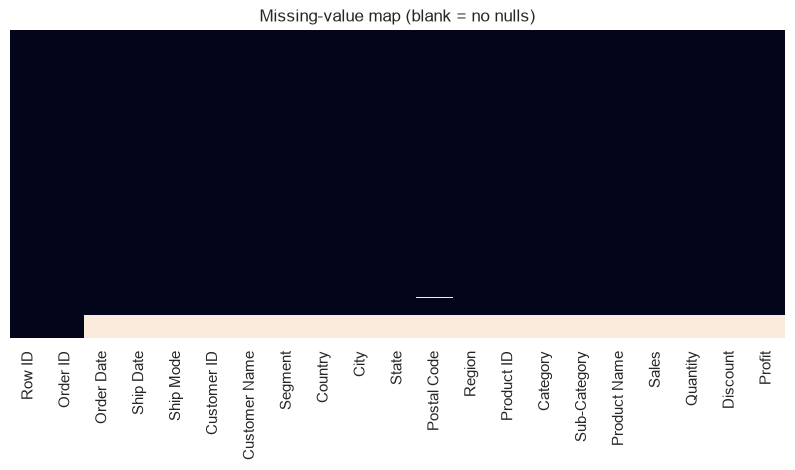

In [4]:
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': df.isnull().mean() * 100
}).sort_values('missing_count', ascending=False)
print(missing[missing.missing_count > 0] if missing.missing_count.sum() else 'No missing values found in any column.')

plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing-value map (blank = no nulls)')
plt.show()

### 3.3 Cleaning steps

In [5]:
# 1. Standardise column names
df.columns = (df.columns.str.strip().str.replace(r'[\s\-]+', '_', regex=True))

# 2. Remove exact duplicates
before = len(df)
df = df.drop_duplicates()
print(f'Duplicates removed: {before - len(df)}')

# 3. Handle null values
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include='object').columns
for c in num_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode()[0])

# 4. Parse dates (handles m/d/Y and other formats)
for c in ['Order_Date', 'Ship_Date']:
    df[c] = pd.to_datetime(df[c], errors='coerce')
df = df.dropna(subset=['Order_Date'])

# 5. Feature engineering
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%b')
df['Year_Month'] = df['Order_Date'].dt.to_period('M').astype(str)
df['Ship_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days
df['Profit_Margin_%'] = np.where(df['Sales'] != 0, df['Profit'] / df['Sales'] * 100, 0)

print('Remaining nulls:', int(df.isnull().sum().sum()))
print('Date range:', df['Order_Date'].min().date(), 'to', df['Order_Date'].max().date())
df.describe().T

Duplicates removed: 504
Remaining nulls: 0
Date range: 2015-01-03 to 2018-12-30


,count,mean,min,25%,50%,75%,max,std
Order_Date,10296,2017-05-03 23:14:15.944056,2015-01-03 00:00:00,2016-06-06 12:00:00,2017-07-19 00:00:00,2018-05-05 00:00:00,2018-12-30 00:00:00,NaN
Ship_Date,10296,2017-04-30 02:18:44.475524,2015-01-07 00:00:00,2016-06-09 18:00:00,2017-06-09 00:00:00,2018-05-09 00:00:00,2019-01-05 00:00:00,NaN
Postal_Code,"10,296.00","55,301.71","1,040.00","23,666.00","57,103.00","90,004.00","99,301.00","31,549.53"
Sales,"10,296.00",224.71,0.44,17.90,54.49,201.00,"22,638.48",614.75
Quantity,"10,296.00",3.77,1.00,2.00,3.00,5.00,14.00,2.20
Discount,"10,296.00",0.16,0.00,0.00,0.20,0.20,0.80,0.20
Profit,"10,296.00",28.07,"-6,599.98",1.90,8.67,28.17,"8,399.98",230.82
Year,"10,296.00","2,016.73","2,015.00","2,016.00","2,017.00","2,018.00","2,018.00",1.11
Month,"10,296.00",7.84,1.00,5.00,9.00,11.00,12.00,3.24
Ship_Days,"10,296.00",-3.87,-263.00,3.00,4.00,5.00,7.00,45.08


## 4. Aggregate Analysis (Category, Region, Segment)

In [6]:
def agg(by):
    g = df.groupby(by).agg(Sales=('Sales','sum'), Profit=('Profit','sum'),
                           Orders=('Order_ID','nunique'), Quantity=('Quantity','sum'))
    g['Margin_%'] = g['Profit'] / g['Sales'] * 100
    return g.sort_values('Sales', ascending=False)

cat_perf = agg('Category');   display(cat_perf)
reg_perf = agg('Region');     display(reg_perf)
seg_perf = agg('Segment');    display(seg_perf)
sub_perf = agg('Sub_Category'); display(sub_perf)

,Sales,Profit,Orders,Quantity,Margin_%
Category,,,,,
Technology,"836,154.03","145,454.95",1544,"6,939.00",17.40
Furniture,"741,999.80","18,451.27",1764,"8,028.00",2.49
Office Supplies,"735,503.01","125,108.08",3810,"23,812.00",17.01


,Sales,Profit,Orders,Quantity,Margin_%
Region,,,,,
West,"741,913.80","111,035.73",1724,"13,172.00",14.97
East,"678,781.24","91,522.78",1401,"10,618.00",13.48
Central,"501,239.89","39,706.36",1175,"8,780.00",7.92
South,"391,721.91","46,749.43",822,"6,209.00",11.93


,Sales,Profit,Orders,Quantity,Margin_%
Segment,,,,,
Consumer,"1,177,857.32","136,736.49",2734,"20,427.00",11.61
Corporate,"706,146.37","91,979.13",1514,"11,608.00",13.03
Home Office,"429,653.15","60,298.68",909,"6,744.00",14.03


,Sales,Profit,Orders,Quantity,Margin_%
Sub_Category,,,,,
Phones,"330,007.05","44,515.73",814,"3,289.00",13.49
Chairs,"328,449.10","26,590.17",576,"2,356.00",8.10
Storage,"223,843.61","21,278.83",777,"3,158.00",9.51
Binders,"219,868.71","32,839.05",1510,"6,880.00",14.94
Tables,"206,965.53","-17,725.48",307,"1,241.00",-8.56
Machines,"189,238.63","3,384.76",112,440.00,1.79
Accessories,"167,380.32","41,936.64",718,"2,976.00",25.05
Copiers,"149,528.03","55,617.82",68,234.00,37.20
Bookcases,"114,880.00","-3,472.56",224,868.00,-3.02


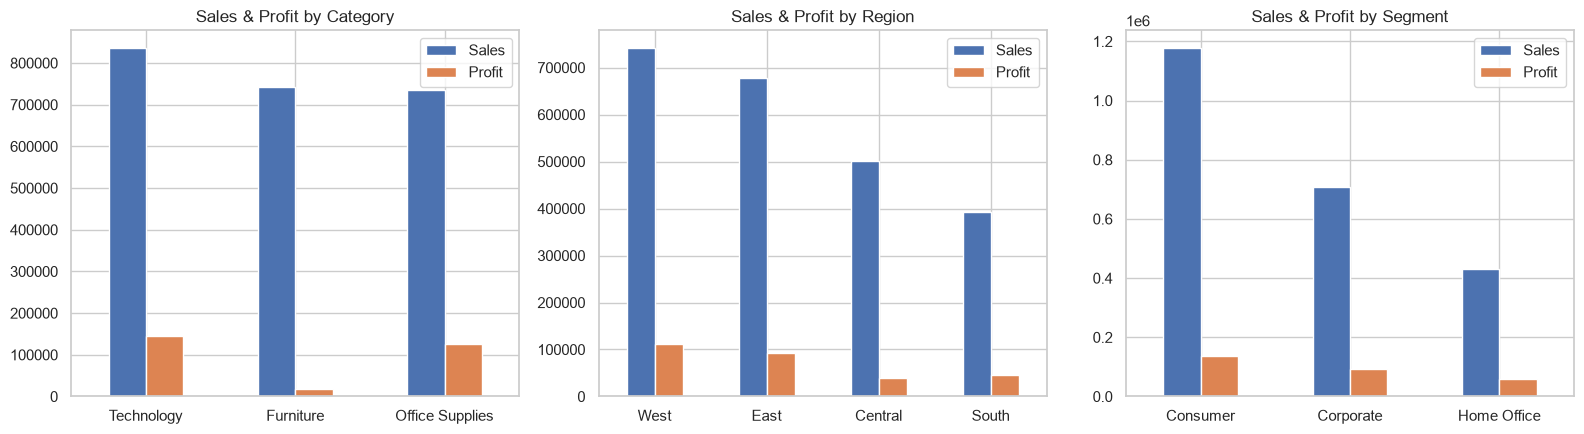

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (name, d) in zip(ax, [('Category', cat_perf), ('Region', reg_perf), ('Segment', seg_perf)]):
    d[['Sales', 'Profit']].plot(kind='bar', ax=a, rot=0)
    a.set_title(f'Sales & Profit by {name}'); a.set_xlabel('')
plt.tight_layout(); plt.show()

In [8]:
# Group by Category x Region x Segment as per task
combo = (df.groupby(['Category', 'Region', 'Segment'])[['Sales', 'Profit']].sum()
           .sort_values('Sales', ascending=False))
combo.head(10)

Sales    Profit
Category        Region  Segment                       
Technology      East    Consumer  135,441.23 19,930.18
                West    Consumer  132,991.75 27,785.57
Office Supplies West    Consumer  126,536.92 27,951.65
Furniture       West    Consumer  119,808.09  4,330.67
                East    Consumer  114,211.80  2,038.11
Office Supplies East    Consumer  101,255.14 19,222.69
                Central Consumer   93,111.48  2,583.14
Furniture       Central Consumer   86,229.22 -3,994.43
                West    Corporate  83,080.11  3,968.67
Office Supplies West    Corporate  77,133.86 18,527.70

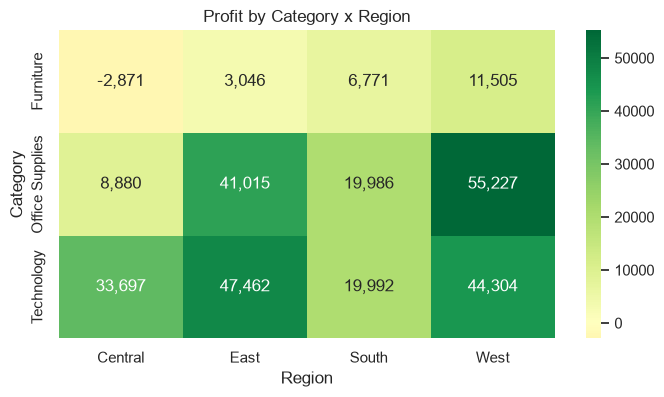

In [9]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.pivot_table(index='Category', columns='Region', values='Profit', aggfunc='sum'),
            annot=True, fmt=',.0f', cmap='RdYlGn', center=0)
plt.title('Profit by Category x Region'); plt.show()

## 5. Customer Purchase Volume

Unique customers: 793


,,Orders,Sales,Profit
Customer_ID,Customer_Name,,,
SM-20320,Sean Miller,5,"25,043.05","-1,980.74"
WB-21850,William Brown,312,"22,616.08","3,331.61"
TC-20980,Tamara Chand,5,"19,052.22","8,981.32"
RB-19360,Raymond Buch,6,"15,117.34","6,976.10"
TA-21385,Tom Ashbrook,4,"14,595.62","4,703.79"
AB-10105,Adrian Barton,10,"14,473.57","5,444.81"
KL-16645,Ken Lonsdale,12,"14,175.23",806.86
SC-20095,Sanjit Chand,9,"14,142.33","5,757.41"
HL-15040,Hunter Lopez,6,"12,873.30","5,622.43"


Top 20% of customers contribute 48.3% of total sales


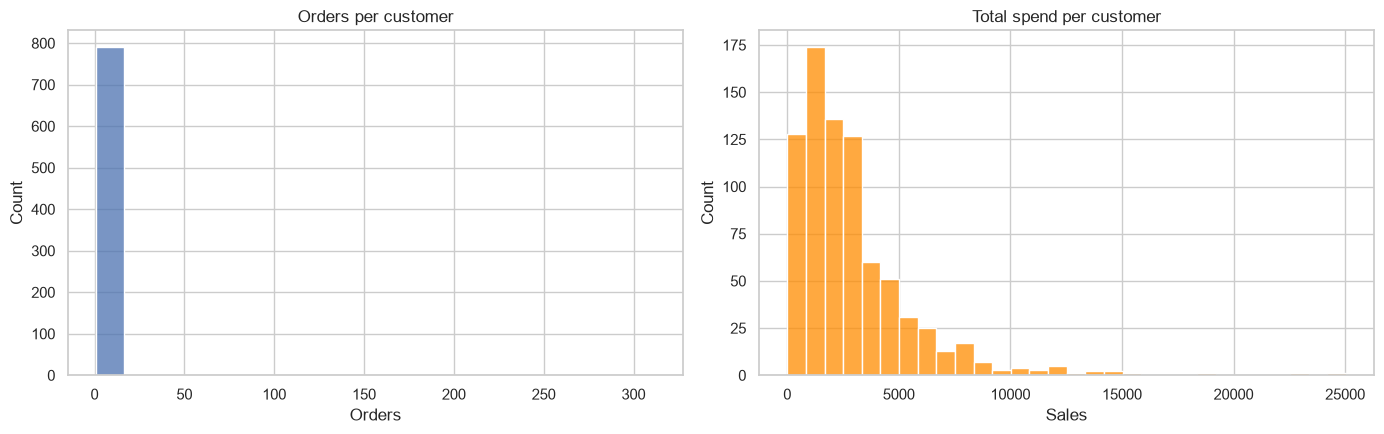

In [10]:
cust = df.groupby(['Customer_ID', 'Customer_Name']).agg(
    Orders=('Order_ID', 'nunique'), Sales=('Sales', 'sum'), Profit=('Profit', 'sum')
).sort_values('Sales', ascending=False)

print('Unique customers:', len(cust))
display(cust.head(10))

top20_share = cust['Sales'].head(int(len(cust)*0.2)).sum() / cust['Sales'].sum() * 100
print(f'Top 20% of customers contribute {top20_share:.1f}% of total sales')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(cust['Orders'], bins=20, ax=ax[0]); ax[0].set_title('Orders per customer')
sns.histplot(cust['Sales'], bins=30, ax=ax[1], color='darkorange'); ax[1].set_title('Total spend per customer')
plt.tight_layout(); plt.show()

## 6. Monthly Seasonality & Sales Velocity

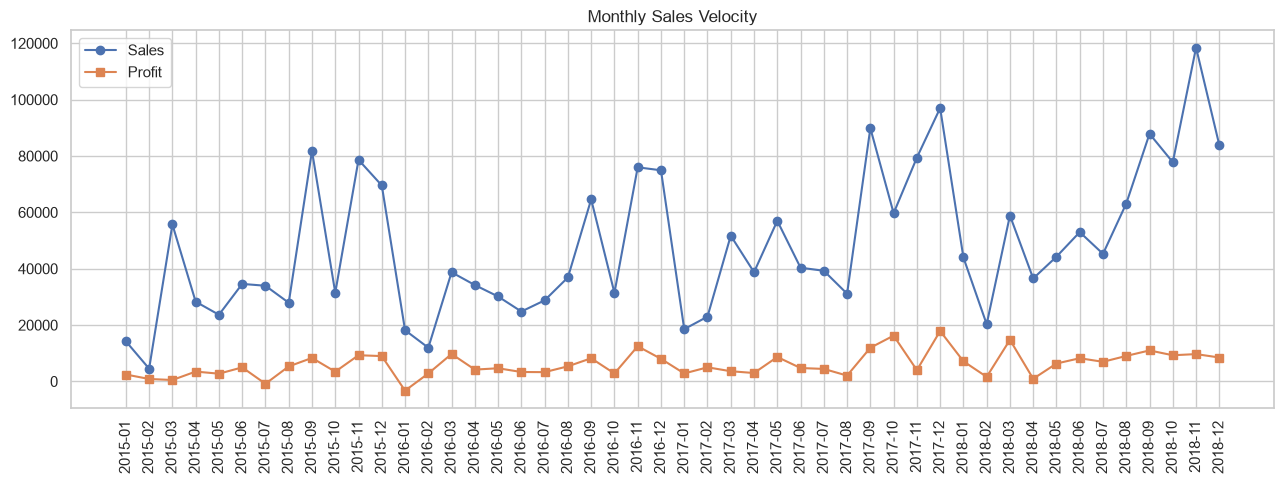

In [11]:
monthly = df.groupby('Year_Month')[['Sales', 'Profit']].sum()
plt.figure(figsize=(13, 5))
plt.plot(monthly.index, monthly['Sales'], marker='o', label='Sales')
plt.plot(monthly.index, monthly['Profit'], marker='s', label='Profit')
plt.xticks(rotation=90); plt.title('Monthly Sales Velocity'); plt.legend(); plt.tight_layout(); plt.show()

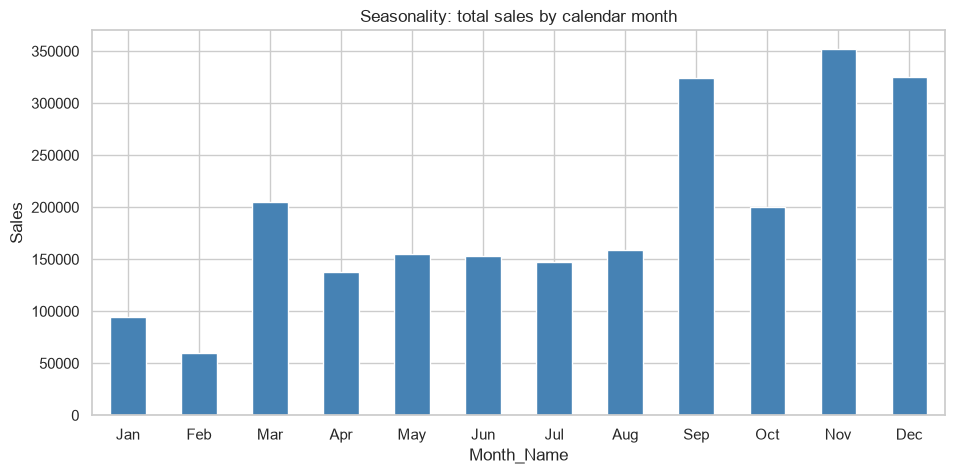

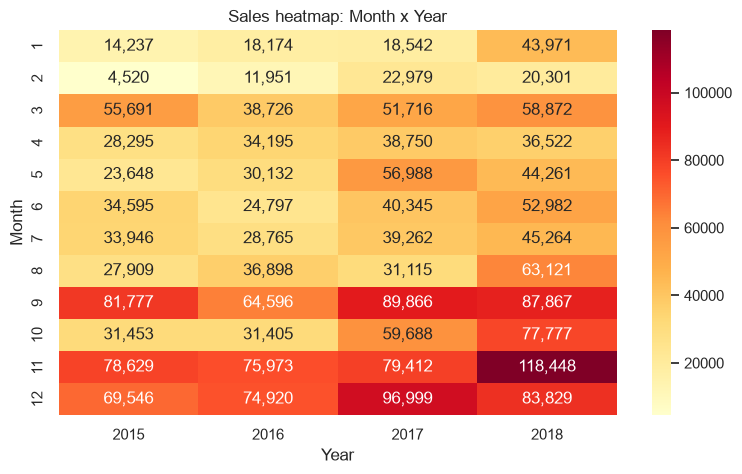

In [12]:
order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
season = df.groupby('Month_Name')[['Sales', 'Profit']].sum().reindex(order)
season['Sales'].plot(kind='bar', color='steelblue', rot=0)
plt.title('Seasonality: total sales by calendar month'); plt.ylabel('Sales'); plt.show()

yearly_month = df.pivot_table(index='Month', columns='Year', values='Sales', aggfunc='sum')
plt.figure(figsize=(9, 5))
sns.heatmap(yearly_month, annot=True, fmt=',.0f', cmap='YlOrRd')
plt.title('Sales heatmap: Month x Year'); plt.show()

## 7. Discount Sensitivity

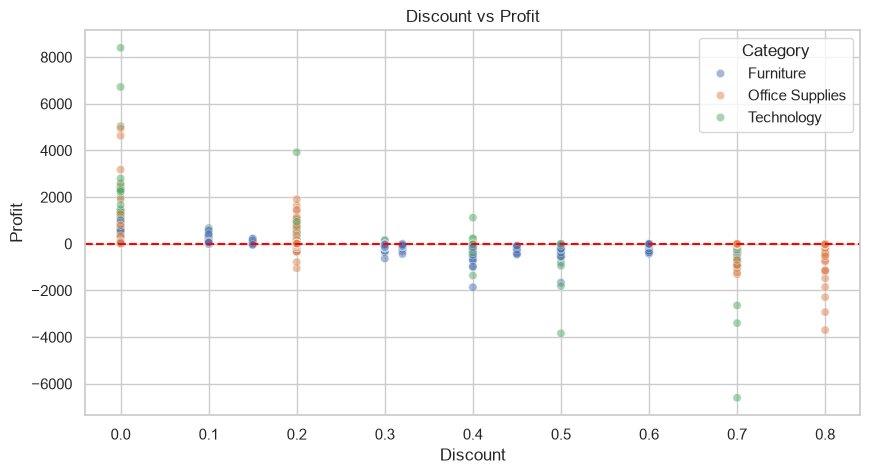

,Orders,Sales,Profit,Avg_Margin
Discount_Band,,,,
0%,4798,"1,087,908.47","320,987.60",34.02
0-10%,94,"54,369.35","9,029.18",15.58
10-20%,4011,"808,608.87","94,373.58",17.36
20-30%,227,"103,226.65","-10,369.28",-11.55
30-50%,310,"195,314.76","-48,447.73",-29.61
>50%,856,"64,228.74","-76,559.05",-113.88


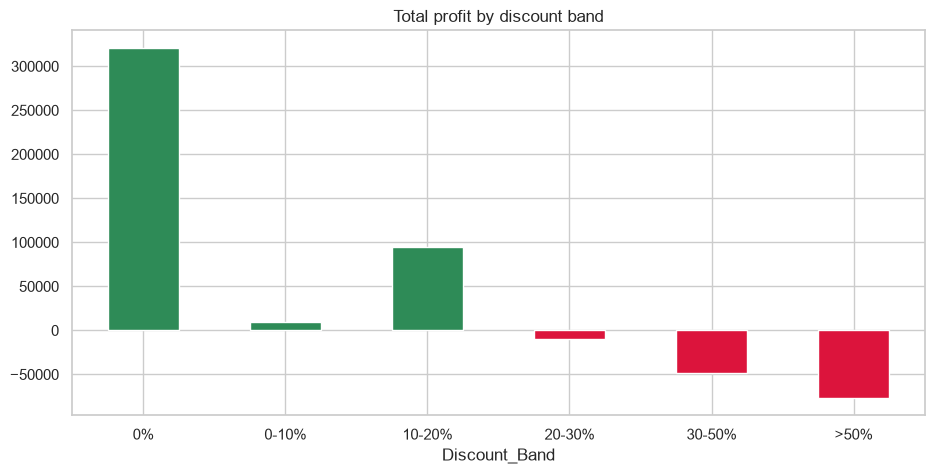

Correlation Discount vs Profit: -0.22


In [13]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=.5)
plt.axhline(0, color='red', ls='--'); plt.title('Discount vs Profit'); plt.show()

df['Discount_Band'] = pd.cut(df['Discount'], bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.5, 1.0],
                             labels=['0%', '0-10%', '10-20%', '20-30%', '30-50%', '>50%'])
disc = df.groupby('Discount_Band').agg(Orders=('Order_ID', 'count'), Sales=('Sales', 'sum'),
                                       Profit=('Profit', 'sum'), Avg_Margin=('Profit_Margin_%', 'mean'))
display(disc)
disc['Profit'].plot(kind='bar', rot=0, color=np.where(disc['Profit'] < 0, 'crimson', 'seagreen'))
plt.title('Total profit by discount band'); plt.show()

print('Correlation Discount vs Profit:', round(df['Discount'].corr(df['Profit']), 3))

## 8. Business Findings (computed from the data)

The cells below compute each key number directly from the dataset, followed by the annotated business interpretation.

### Finding 1 – Category revenue and profitability

In [14]:
top_cat = cat_perf.index[0]; best_margin = cat_perf['Margin_%'].idxmax(); worst_margin = cat_perf['Margin_%'].idxmin()
print(f"{top_cat} is the top revenue category ({cat_perf.loc[top_cat,'Sales']:,.0f}, "
      f"{cat_perf.loc[top_cat,'Sales']/cat_perf.Sales.sum()*100:.1f}% of sales).")
print(f"Highest margin: {best_margin} ({cat_perf.loc[best_margin,'Margin_%']:.1f}%); "
      f"lowest margin: {worst_margin} ({cat_perf.loc[worst_margin,'Margin_%']:.1f}%).")

Technology is the top revenue category (836,154, 36.1% of sales).
Highest margin: Technology (17.4%); lowest margin: Furniture (2.5%).


**Takeaway 1:** Revenue leadership does not equal profit leadership. Category strategy should be steered by margin as well as sales volume – protect high-margin categories and review pricing and cost in the low-margin one.

### Finding 2 – Seasonality

In [15]:
peak = season['Sales'].idxmax(); low = season['Sales'].idxmin()
q4 = season.loc[['Oct','Nov','Dec'], 'Sales'].sum() / season['Sales'].sum() * 100
print(f"Peak month: {peak}; weakest month: {low}; Q4 (Oct-Dec) share of sales: {q4:.1f}%.")
print('Top 3 months:', list(season['Sales'].nlargest(3).index))

Peak month: Nov; weakest month: Feb; Q4 (Oct-Dec) share of sales: 38.0%.
Top 3 months: ['Nov', 'Dec', 'Sep']


**Takeaway 2:** Sales are strongly seasonal with a year-end surge (Sep–Dec) and a weak start of the year. Inventory, staffing and marketing budgets should be front-loaded before Q4, with promotions used to lift the slow Jan–Feb period.

### Finding 3 – Discount sensitivity

In [16]:
loss_bands = disc[disc['Profit'] < 0]
print('Discount bands with net loss:', list(loss_bands.index))
neg_share = (df['Profit'] < 0).mean() * 100
print(f"{neg_share:.1f}% of order lines are loss-making; loss-making lines average discount "
      f"{df.loc[df.Profit<0,'Discount'].mean()*100:.1f}% vs {df.loc[df.Profit>=0,'Discount'].mean()*100:.1f}% for profitable lines.")

Discount bands with net loss: ['20-30%', '30-50%', '>50%']
18.2% of order lines are loss-making; loss-making lines average discount 48.1% vs 8.6% for profitable lines.


**Takeaway 3:** Profit falls as discounts deepen, and heavy discount bands turn net-negative. A discount cap (about 20%) with manager approval above it would remove most avoidable losses.

### Finding 4 – Loss-making sub-categories and regions

In [17]:
losers = sub_perf[sub_perf['Profit'] < 0]
print('Loss-making sub-categories:'); display(losers[['Sales', 'Profit', 'Margin_%']])
print('Best region by profit:', reg_perf['Profit'].idxmax(), '| Weakest region by margin:', reg_perf['Margin_%'].idxmin())

Loss-making sub-categories:


,Sales,Profit,Margin_%
Sub_Category,,,
Tables,"206,965.53","-17,725.48",-8.56
Bookcases,"114,880.00","-3,472.56",-3.02
Supplies,"46,673.54","-1,189.10",-2.55


Best region by profit: West | Weakest region by margin: Central


**Takeaway 4:** A few sub-categories (and weaker regions) destroy profit despite healthy sales. These should be repriced, have discounts restricted, or be reviewed for supplier cost; the best region's practices can be replicated elsewhere.

### Finding 5 – Customer concentration and segments

In [18]:
print(f'Top 20% of customers = {top20_share:.1f}% of revenue.')
print('Largest segment:', seg_perf.index[0], f"({seg_perf.iloc[0]['Sales']/seg_perf.Sales.sum()*100:.1f}% of sales)")
print(f"Average orders per customer: {cust['Orders'].mean():.1f}; median spend: {cust['Sales'].median():,.0f}")

Top 20% of customers = 48.3% of revenue.
Largest segment: Consumer (50.9% of sales)
Average orders per customer: 6.7; median spend: 2,256


**Takeaway 5:** Revenue is concentrated in a minority of repeat customers, with the Consumer segment the largest. Loyalty programmes, retention offers and account management for top customers will protect the revenue base more cheaply than acquiring new customers.

## 9. Executive Summary
1. **Category:** Revenue leader and margin leader differ – optimise for profit, not just sales.
2. **Seasonality:** Strong Q4 peak and early-year dip – plan inventory and campaigns accordingly.
3. **Discounts:** Deep discounts drive net losses – introduce discount caps and approval.
4. **Loss-makers:** Specific sub-categories/regions drag profit – reprice or restructure.
5. **Customers:** Revenue concentrated in top customers/segment – invest in retention.

*Figures quoted in the findings cells above are generated from the data at run time.*